Name : Raj Gajare
Sec-Bat : B3-B4
Roll No : 56

# BDA Lab Project: Air Quality Index (AQI) Analysis for Indian Cities

**Aim:** To analyse the Air Quality Index (AQI) data of Indian cities using the big data tools and techniques of the BDA lab: data cleaning and statistical analysis (Practical 1), Map-Reduce with PySpark RDD (Practical 7), Spark DataFrame / SQL, and K-Means clustering (Practical 8 Part B). Trends and visualizations are shown with plots.

**Dataset:** Air Quality Data in India (2015-2020), file `city_day.csv`
Link: https://www.kaggle.com/datasets/rohanrao/air-quality-data-in-india

**Contents**
1. Load the data
2. Data cleaning and statistical analysis
3. Visualization and trends
4. Map-Reduce using PySpark RDD
5. Analysis using Spark DataFrame and Spark SQL
6. Clustering of cities using K-Means (Spark MLlib)
7. Files for the Streamlit dashboard
8. Run Streamlit directly from Colab (optional)
9. Conclusion

# 1. Load the data

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

In [3]:
from google.colab import files
uploaded = files.upload()   # select city_day.csv

Saving city_day.csv to city_day.csv


In [4]:
df = pd.read_csv("city_day.csv")

# rename PM2.5 to PM25 (a dot in a column name causes problems in Spark)
df = df.rename(columns={"PM2.5": "PM25"})
df["Date"] = pd.to_datetime(df["Date"])

print("Rows   :", df.shape[0])
print("Columns:", df.shape[1])
print("Cities :", df["City"].nunique())
print("Dates  :", df["Date"].min().date(), "to", df["Date"].max().date())
df.head()

Rows   : 29531
Columns: 16
Cities : 26
Dates  : 2015-01-01 to 2020-07-01


,City,Date,PM25,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


# 2. Data cleaning and statistical analysis

### 2.1 Missing values

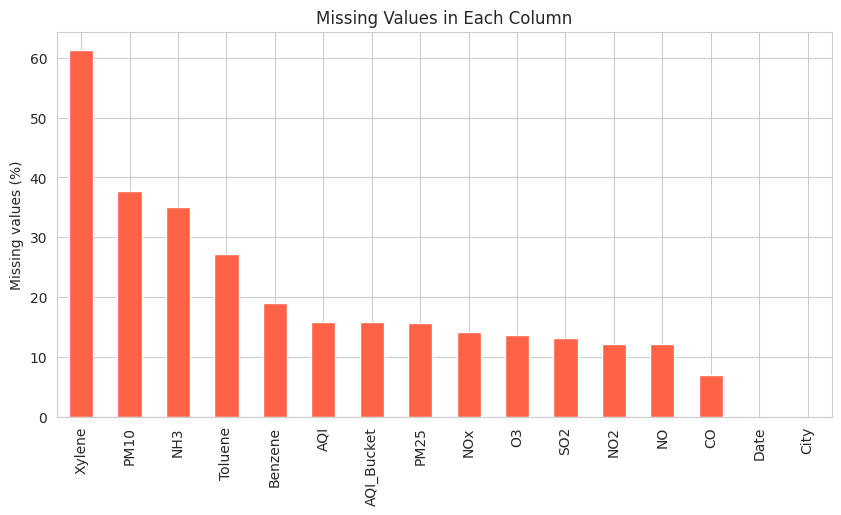

In [5]:
pollutants = ["PM25", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene"]

missing = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
missing.plot(kind="bar", color="tomato")
plt.ylabel("Missing values (%)")
plt.title("Missing Values in Each Column")
plt.show()

### 2.2 Clean the dataset

In [6]:
# 1. remove duplicate rows
df = df.drop_duplicates()

# 2. remove rows where AQI is missing
df = df.dropna(subset=["AQI"])

# 3. fill missing pollutant values with the median of that city,
#    and with the overall median if a city has no data for that pollutant
for col in pollutants:
    df[col] = df[col].fillna(df.groupby("City")[col].transform("median"))
    df[col] = df[col].fillna(df[col].median())


# 4. AQI category from the AQI value (CPCB scale)
def get_bucket(aqi):
    if aqi <= 50:
        return "Good"
    elif aqi <= 100:
        return "Satisfactory"
    elif aqi <= 200:
        return "Moderate"
    elif aqi <= 300:
        return "Poor"
    elif aqi <= 400:
        return "Very Poor"
    return "Severe"


df["AQI_Bucket"] = df["AQI"].apply(get_bucket)

# 5. year and month columns
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month

print("Rows after cleaning:", len(df))
print("Missing values left:", df[pollutants + ["AQI"]].isnull().sum().sum())

Rows after cleaning: 24850
Missing values left: 0


### 2.3 Statistical analysis

In [7]:
main_cols = ["PM25", "PM10", "NO2", "CO", "SO2", "O3", "AQI"]

df[main_cols].describe().round(2)

,PM25,PM10,NO2,CO,SO2,O3,AQI
count,24850.00,24850.00,24850.00,24850.00,24850.00,24850.00,24850.00
mean,67.10,113.43,28.76,2.32,14.41,34.74,166.46
std,62.29,78.58,24.52,7.02,17.31,21.46,140.70
min,0.04,0.03,0.01,0.00,0.01,0.01,13.00
25%,29.48,58.32,11.83,0.58,5.79,19.44,81.00
50%,49.24,100.14,21.84,0.92,9.25,31.18,118.00
75%,79.58,134.22,37.94,1.47,15.22,45.41,208.00
max,914.94,917.08,362.21,175.81,186.08,257.73,2049.00


In [8]:
print("Average AQI :", round(df["AQI"].mean(), 2))
print("Maximum AQI :", df["AQI"].max())
print("Minimum AQI :", df["AQI"].min())
print()
print("Average values of pollutants")
print(df[main_cols].mean().round(2))

Average AQI : 166.46
Maximum AQI : 2049.0
Minimum AQI : 13.0

Average values of pollutants
PM25     67.10
PM10    113.43
NO2      28.76
CO        2.32
SO2      14.41
O3       34.74
AQI     166.46
dtype: float64


### 2.4 Correlation matrix

In [9]:
corr_cols = ["PM25", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3", "AQI"]
corr = df[corr_cols].corr()

corr.round(2)

,PM25,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,AQI
PM25,1.00,0.57,0.46,0.37,0.41,0.19,0.09,0.13,0.17,0.66
PM10,0.57,1.00,0.46,0.38,0.46,0.13,0.04,0.19,0.21,0.49
NO,0.46,0.46,1.00,0.47,0.79,0.13,0.22,0.19,0.02,0.45
NO2,0.37,0.38,0.47,1.00,0.62,0.13,0.37,0.41,0.30,0.53
NOx,0.41,0.46,0.79,0.62,1.00,0.10,0.25,0.23,0.10,0.47
NH3,0.19,0.13,0.13,0.13,0.10,1.00,-0.02,-0.08,0.08,0.10
CO,0.09,0.04,0.22,0.37,0.25,-0.02,1.00,0.49,0.04,0.68
SO2,0.13,0.19,0.19,0.41,0.23,-0.08,0.49,1.00,0.17,0.49
O3,0.17,0.21,0.02,0.30,0.10,0.08,0.04,0.17,1.00,0.20
AQI,0.66,0.49,0.45,0.53,0.47,0.10,0.68,0.49,0.20,1.00


### 2.5 Save the cleaned dataset into Excel / CSV

In [10]:
df["Date"] = df["Date"].dt.strftime("%Y-%m-%d")

df.to_excel("AQI_Cleaned.xlsx", index=False)
df.to_csv("aqi_cleaned.csv", index=False)
print("Cleaned files saved successfully")

from google.colab import files
files.download("AQI_Cleaned.xlsx")

Cleaned files saved successfully


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 3. Visualization and trends

### 3.1 AQI distribution and categories

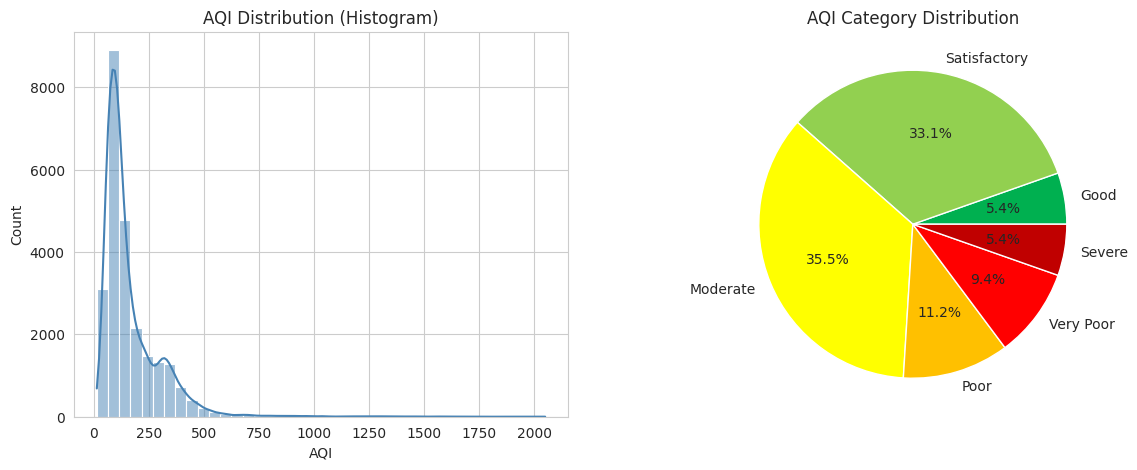

In [11]:
order = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
colors = ["#00b050", "#92d050", "#ffff00", "#ffc000", "#ff0000", "#c00000"]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# histogram
sns.histplot(df["AQI"], bins=40, kde=True, ax=ax[0], color="steelblue")
ax[0].set_title("AQI Distribution (Histogram)")

# pie chart
counts = df["AQI_Bucket"].value_counts().reindex(order)
ax[1].pie(counts.values, labels=counts.index, colors=colors, autopct="%1.1f%%")
ax[1].set_title("AQI Category Distribution")

plt.show()

### 3.2 Most polluted and cleanest cities

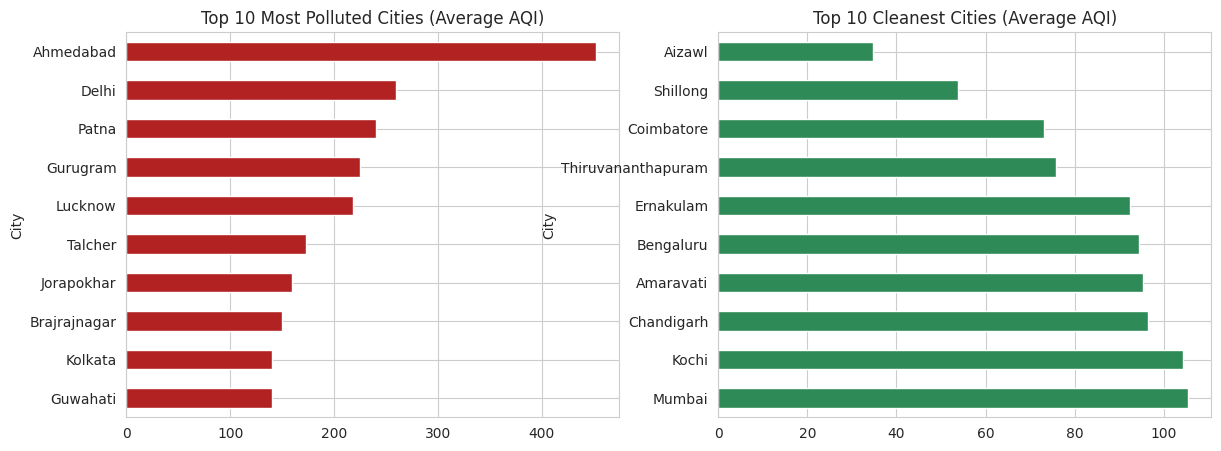

Most polluted city: Ahmedabad 452.1
Cleanest city     : Aizawl 34.8


In [12]:
city_avg = df.groupby("City")["AQI"].mean().sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

city_avg.head(10).sort_values().plot(kind="barh", ax=ax[0], color="firebrick")
ax[0].set_title("Top 10 Most Polluted Cities (Average AQI)")

city_avg.tail(10).plot(kind="barh", ax=ax[1], color="seagreen")
ax[1].set_title("Top 10 Cleanest Cities (Average AQI)")

plt.show()
print("Most polluted city:", city_avg.index[0], round(city_avg.iloc[0], 1))
print("Cleanest city     :", city_avg.index[-1], round(city_avg.iloc[-1], 1))

### 3.3 Yearly trend

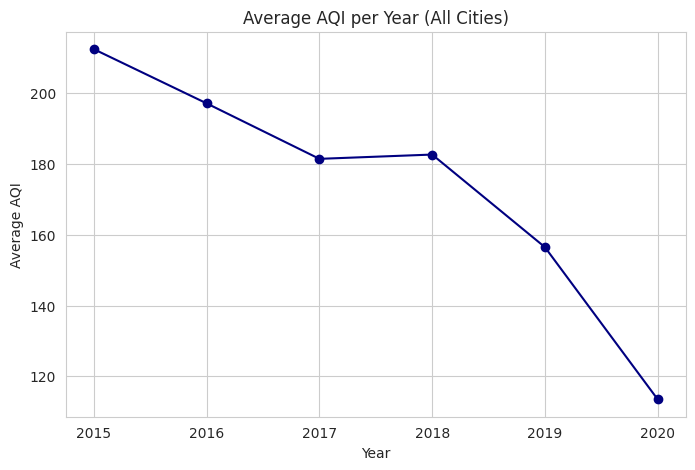

Year
2015    212.5
2016    197.2
2017    181.5
2018    182.7
2019    156.5
2020    113.5
Name: AQI, dtype: float64


In [13]:
yearly = df.groupby("Year")["AQI"].mean()

plt.figure(figsize=(8, 5))
plt.plot(yearly.index, yearly.values, marker="o", color="navy")
plt.xlabel("Year")
plt.ylabel("Average AQI")
plt.title("Average AQI per Year (All Cities)")
plt.show()
print(yearly.round(1))

### 3.4 Seasonal trend (month-wise)

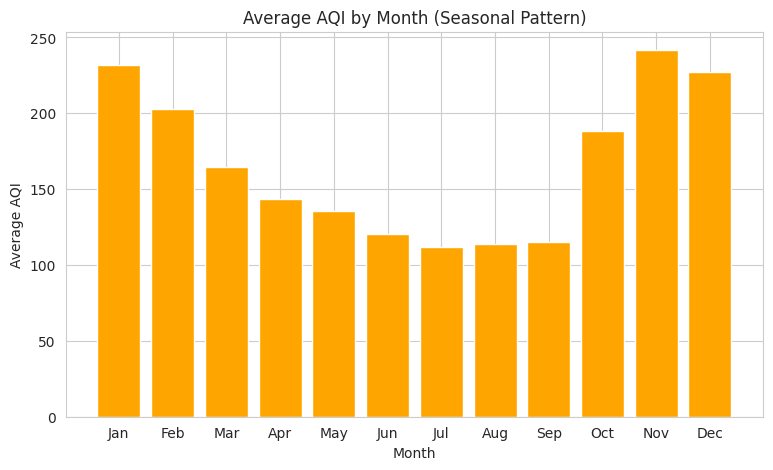

Worst month: Nov  Best month: Jul


In [14]:
monthly = df.groupby("Month")["AQI"].mean()
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.figure(figsize=(9, 5))
plt.bar(monthly.index, monthly.values, color="orange")
plt.xticks(range(1, 13), month_names)
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.title("Average AQI by Month (Seasonal Pattern)")
plt.show()
print("Worst month:", month_names[monthly.idxmax() - 1], " Best month:", month_names[monthly.idxmin() - 1])

### 3.5 Pollutants and AQI

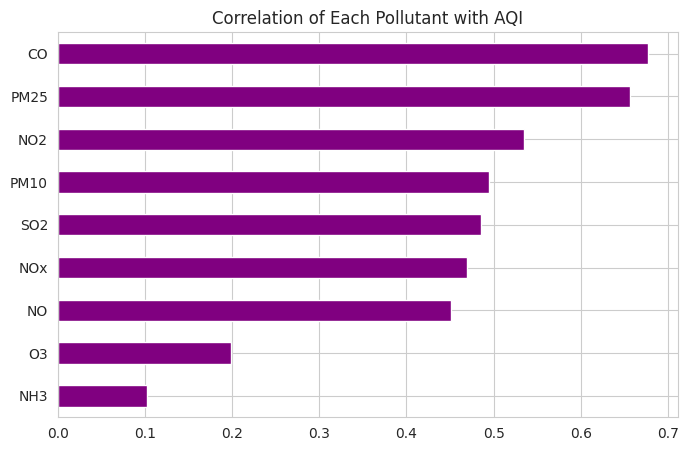

In [15]:
# which pollutant is most related to AQI
corr["AQI"].drop("AQI").sort_values().plot(kind="barh", figsize=(8, 5), color="purple")
plt.title("Correlation of Each Pollutant with AQI")
plt.show()

### 3.6 Effect of the COVID-19 lockdown (April-May 2019 vs 2020)

# 4. Map-Reduce using PySpark RDD (Practical 7)

Input -> MAP -> SHUFFLE -> REDUCE -> Output

In [16]:
!pip install pyspark -q

In [17]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = SparkSession.builder \
    .appName("AQI Analysis") \
    .master("local[*]") \
    .getOrCreate()

sc = spark.sparkContext

In [18]:
import csv

file = open("aqi_cleaned.csv", "r")
reader = csv.reader(file)

header = next(reader)
data = list(reader)
file.close()

rdd = sc.parallelize(data)

print("Total Records:", rdd.count())
print("Sample Data:", rdd.take(2))

Total Records: 24850
Sample Data: [['Ahmedabad', '2015-01-29', '83.13', '107.67', '6.93', '28.71', '33.72', '17.055', '6.93', '49.52', '59.76', '0.02', '0.0', '3.14', '209.0', 'Poor', '2015', '1'], ['Ahmedabad', '2015-01-30', '79.84', '107.67', '13.85', '28.68', '41.08', '17.055', '13.85', '48.49', '97.07', '0.04', '0.0', '4.81', '328.0', 'Very Poor', '2015', '1']]


In [19]:
city_i = header.index("City")
aqi_i = header.index("AQI")
bucket_i = header.index("AQI_Bucket")
year_i = header.index("Year")
month_i = header.index("Month")

### a) Number of days and average AQI per city

In [20]:
city_aqi = rdd.map(
    lambda x: (x[city_i], (float(x[aqi_i]), 1))
)

city_total = city_aqi.reduceByKey(
    lambda a, b: (a[0] + b[0], a[1] + b[1])
)

rdd_average = city_total.map(
    lambda x: (x[0], x[1][1], round(x[1][0] / x[1][1], 2))
)

print("(City, Days, Average AQI):")
for r in sorted(rdd_average.collect(), key=lambda r: r[2], reverse=True):
    print(r)

(City, Days, Average AQI):
('Ahmedabad', 1334, 452.12)
('Delhi', 1999, 259.49)
('Patna', 1459, 240.78)
('Gurugram', 1453, 225.12)
('Lucknow', 1893, 217.97)
('Talcher', 698, 172.89)
('Jorapokhar', 771, 159.25)
('Brajrajnagar', 713, 150.28)
('Kolkata', 754, 140.57)
('Guwahati', 495, 140.11)
('Jaipur', 1094, 133.68)
('Bhopal', 278, 132.83)
('Amritsar', 1126, 119.92)
('Visakhapatnam', 1171, 117.27)
('Chennai', 1884, 114.5)
('Hyderabad', 1880, 109.21)
('Mumbai', 775, 105.35)
('Kochi', 158, 104.28)
('Chandigarh', 299, 96.5)
('Amaravati', 841, 95.3)
('Bengaluru', 1910, 94.32)
('Ernakulam', 153, 92.36)
('Thiruvananthapuram', 1052, 75.88)
('Coimbatore', 344, 73.02)
('Shillong', 205, 53.8)
('Aizawl', 111, 34.77)


### b) Highest and lowest AQI per city

In [21]:
city_max = rdd.map(lambda x: (x[city_i], float(x[aqi_i]))).reduceByKey(lambda a, b: max(a, b))
city_min = rdd.map(lambda x: (x[city_i], float(x[aqi_i]))).reduceByKey(lambda a, b: min(a, b))

print("Highest AQI per City:")
print(sorted(city_max.collect(), key=lambda r: r[1], reverse=True))
print()
print("Lowest AQI per City:")
print(sorted(city_min.collect(), key=lambda r: r[1]))

Highest AQI per City:
[('Ahmedabad', 2049.0), ('Guwahati', 956.0), ('Gurugram', 891.0), ('Amritsar', 869.0), ('Hyderabad', 737.0), ('Delhi', 716.0), ('Lucknow', 707.0), ('Patna', 619.0), ('Jorapokhar', 604.0), ('Talcher', 570.0), ('Kolkata', 475.0), ('Jaipur', 457.0), ('Chennai', 449.0), ('Visakhapatnam', 387.0), ('Brajrajnagar', 355.0), ('Bengaluru', 352.0), ('Chandigarh', 335.0), ('Amaravati', 312.0), ('Bhopal', 312.0), ('Mumbai', 307.0), ('Kochi', 277.0), ('Thiruvananthapuram', 230.0), ('Shillong', 182.0), ('Ernakulam', 180.0), ('Coimbatore', 120.0), ('Aizawl', 92.0)]

Lowest AQI per City:
[('Talcher', 13.0), ('Shillong', 14.0), ('Aizawl', 18.0), ('Amritsar', 20.0), ('Bengaluru', 20.0), ('Brajrajnagar', 22.0), ('Hyderabad', 22.0), ('Visakhapatnam', 23.0), ('Amaravati', 24.0), ('Guwahati', 25.0), ('Coimbatore', 26.0), ('Chandigarh', 26.0), ('Kolkata', 26.0), ('Jorapokhar', 27.0), ('Delhi', 29.0), ('Chennai', 30.0), ('Thiruvananthapuram', 32.0), ('Bhopal', 37.0), ('Gurugram', 38.0), (

### c) Number of days in each AQI category

In [22]:
rdd_bucket = rdd.map(lambda x: (x[bucket_i], 1)).reduceByKey(lambda a, b: a + b)

print("Days per AQI Category:")
print(rdd_bucket.collect())

Days per AQI Category:
[('Very Poor', 2337), ('Satisfactory', 8224), ('Good', 1341), ('Poor', 2781), ('Severe', 1338), ('Moderate', 8829)]


### d) Average AQI per year and per month (trends)

In [23]:
def average_by(index):
    pairs = rdd.map(lambda x: (x[index], (float(x[aqi_i]), 1)))
    total = pairs.reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
    return total.map(lambda x: (x[0], round(x[1][0] / x[1][1], 2)))


print("Average AQI per Year:")
print(sorted(average_by(year_i).collect()))
print()
print("Average AQI per Month:")
print(sorted(average_by(month_i).collect(), key=lambda r: int(r[0])))

Average AQI per Year:
[('2015', 212.46), ('2016', 197.15), ('2017', 181.47), ('2018', 182.68), ('2019', 156.52), ('2020', 113.52)]

Average AQI per Month:
[('1', 231.67), ('2', 202.91), ('3', 164.74), ('4', 143.36), ('5', 135.49), ('6', 120.2), ('7', 111.85), ('8', 113.61), ('9', 115.19), ('10', 188.61), ('11', 241.68), ('12', 227.08)]


### e) City with the highest and lowest average AQI

In [24]:
most_polluted = rdd_average.reduce(lambda a, b: a if a[2] > b[2] else b)
cleanest = rdd_average.reduce(lambda a, b: a if a[2] < b[2] else b)

print("Most Polluted City:", most_polluted)
print("Cleanest City     :", cleanest)

Most Polluted City: ('Ahmedabad', 1334, 452.12)
Cleanest City     : ('Aizawl', 111, 34.77)


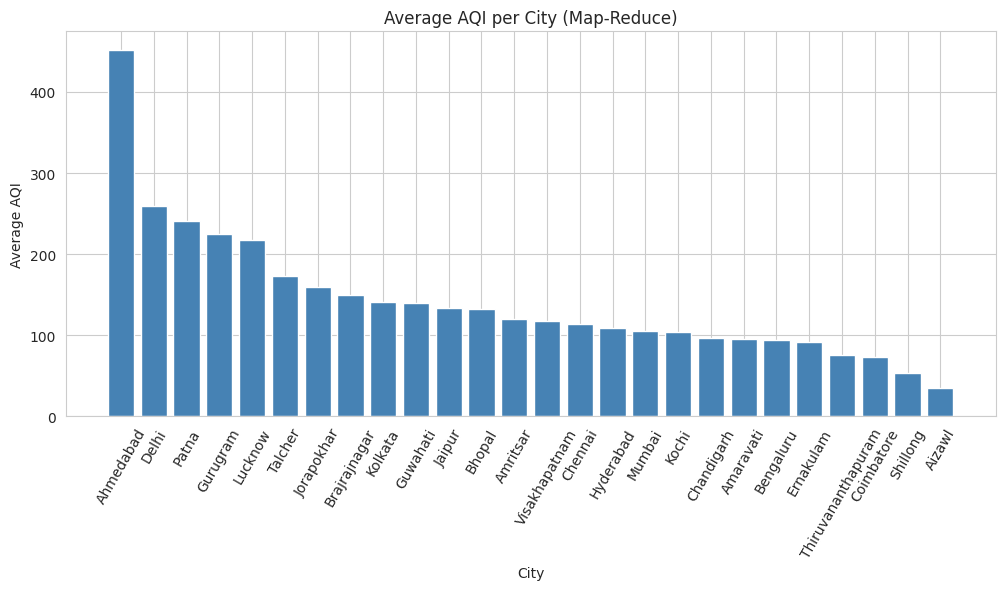

In [25]:
# visualization of the Map-Reduce result
result = sorted(rdd_average.collect(), key=lambda r: r[2], reverse=True)

cities = [x[0] for x in result]
values = [x[2] for x in result]

plt.figure(figsize=(12, 5))
plt.bar(cities, values, color="steelblue")
plt.xlabel("City")
plt.ylabel("Average AQI")
plt.title("Average AQI per City (Map-Reduce)")
plt.xticks(rotation=60)
plt.show()

# 5. Analysis using Spark DataFrame and Spark SQL

In [26]:
sdf = spark.read.csv("aqi_cleaned.csv", header=True, inferSchema=True)

print("Rows:", sdf.count())
sdf.printSchema()
sdf.createOrReplaceTempView("aqi")

Rows: 24850
root
 |-- City: string (nullable = true)
 |-- Date: date (nullable = true)
 |-- PM25: double (nullable = true)
 |-- PM10: double (nullable = true)
 |-- NO: double (nullable = true)
 |-- NO2: double (nullable = true)
 |-- NOx: double (nullable = true)
 |-- NH3: double (nullable = true)
 |-- CO: double (nullable = true)
 |-- SO2: double (nullable = true)
 |-- O3: double (nullable = true)
 |-- Benzene: double (nullable = true)
 |-- Toluene: double (nullable = true)
 |-- Xylene: double (nullable = true)
 |-- AQI: double (nullable = true)
 |-- AQI_Bucket: string (nullable = true)
 |-- Year: integer (nullable = true)
 |-- Month: integer (nullable = true)



### a) Average, maximum and minimum AQI per city

In [27]:
city_stats = sdf.groupBy("City").agg(
    F.count("*").alias("Days"),
    F.round(F.avg("AQI"), 2).alias("Avg_AQI"),
    F.max("AQI").alias("Max_AQI"),
    F.min("AQI").alias("Min_AQI")
).orderBy(F.col("Avg_AQI").desc())

city_stats.show(30)

+------------------+----+-------+-------+-------+
|              City|Days|Avg_AQI|Max_AQI|Min_AQI|
+------------------+----+-------+-------+-------+
|         Ahmedabad|1334| 452.12| 2049.0|   48.0|
|             Delhi|1999| 259.49|  716.0|   29.0|
|             Patna|1459| 240.78|  619.0|   53.0|
|          Gurugram|1453| 225.12|  891.0|   38.0|
|           Lucknow|1893| 217.97|  707.0|   39.0|
|           Talcher| 698| 172.89|  570.0|   13.0|
|        Jorapokhar| 771| 159.25|  604.0|   27.0|
|      Brajrajnagar| 713| 150.28|  355.0|   22.0|
|           Kolkata| 754| 140.57|  475.0|   26.0|
|          Guwahati| 495| 140.11|  956.0|   25.0|
|            Jaipur|1094| 133.68|  457.0|   43.0|
|            Bhopal| 278| 132.83|  312.0|   37.0|
|          Amritsar|1126| 119.92|  869.0|   20.0|
|     Visakhapatnam|1171| 117.27|  387.0|   23.0|
|           Chennai|1884|  114.5|  449.0|   30.0|
|         Hyderabad|1880| 109.21|  737.0|   22.0|
|            Mumbai| 775| 105.35|  307.0|   40.0|


### b) Most polluted and cleanest city

In [28]:
print("Most Polluted City:")
city_stats.show(1)

print("Cleanest City:")
city_stats.orderBy(F.col("Avg_AQI").asc()).show(1)

Most Polluted City:
+---------+----+-------+-------+-------+
|     City|Days|Avg_AQI|Max_AQI|Min_AQI|
+---------+----+-------+-------+-------+
|Ahmedabad|1334| 452.12| 2049.0|   48.0|
+---------+----+-------+-------+-------+
only showing top 1 row
Cleanest City:
+------+----+-------+-------+-------+
|  City|Days|Avg_AQI|Max_AQI|Min_AQI|
+------+----+-------+-------+-------+
|Aizawl| 111|  34.77|   92.0|   18.0|
+------+----+-------+-------+-------+
only showing top 1 row


### c) Number of days in each AQI category

In [29]:
bucket_df = sdf.groupBy("AQI_Bucket").agg(F.count("*").alias("Days")).orderBy(F.col("Days").desc())
bucket_df.show()

+------------+----+
|  AQI_Bucket|Days|
+------------+----+
|    Moderate|8829|
|Satisfactory|8224|
|        Poor|2781|
|   Very Poor|2337|
|        Good|1341|
|      Severe|1338|
+------------+----+



### d) Yearly and monthly trend

In [30]:
year_df = sdf.groupBy("Year").agg(F.round(F.avg("AQI"), 2).alias("Avg_AQI")).orderBy("Year")
year_df.show()

month_df = sdf.groupBy("Month").agg(F.round(F.avg("AQI"), 2).alias("Avg_AQI")).orderBy("Month")
month_df.show(12)

+----+-------+
|Year|Avg_AQI|
+----+-------+
|2015| 212.46|
|2016| 197.15|
|2017| 181.47|
|2018| 182.68|
|2019| 156.52|
|2020| 113.52|
+----+-------+

+-----+-------+
|Month|Avg_AQI|
+-----+-------+
|    1| 231.67|
|    2| 202.91|
|    3| 164.74|
|    4| 143.36|
|    5| 135.49|
|    6|  120.2|
|    7| 111.85|
|    8| 113.61|
|    9| 115.19|
|   10| 188.61|
|   11| 241.68|
|   12| 227.08|
+-----+-------+



### e) Average pollutant levels per city

In [31]:
pollutant_df = sdf.groupBy("City").agg(
    F.round(F.avg("PM25"), 2).alias("PM25"),
    F.round(F.avg("PM10"), 2).alias("PM10"),
    F.round(F.avg("NO2"), 2).alias("NO2"),
    F.round(F.avg("CO"), 2).alias("CO"),
    F.round(F.avg("SO2"), 2).alias("SO2"),
    F.round(F.avg("O3"), 2).alias("O3")
).orderBy(F.col("PM25").desc())

pollutant_df.show(30)

+------------------+------+------+-----+-----+-----+-----+
|              City|  PM25|  PM10|  NO2|   CO|  SO2|   O3|
+------------------+------+------+-----+-----+-----+-----+
|             Patna| 124.7|119.16|39.06| 1.59|23.84|39.88|
|             Delhi|117.54|232.35|50.76| 1.99|15.84|51.07|
|          Gurugram|115.52|183.56|23.73| 1.29| 9.38|35.02|
|           Lucknow|109.77|100.14|33.88| 1.75| 8.02| 37.1|
|         Ahmedabad| 67.86|109.19|60.29|22.16|55.71|39.25|
|           Kolkata| 64.65|116.08| 40.8| 0.85| 8.22|30.63|
|      Brajrajnagar| 63.81|123.46|16.96| 1.84|10.23|15.63|
|        Jorapokhar| 62.43|151.96|  9.3|  0.6|32.17| 32.7|
|          Guwahati| 61.46|113.82|13.54| 0.73|14.57|25.08|
|           Talcher| 61.22|165.95|12.79| 1.81|28.93|16.99|
|            Jaipur| 54.68|123.78|32.46| 0.81| 11.1|46.98|
|          Amritsar| 54.28|114.65|18.45| 0.56| 8.08|22.13|
|            Bhopal| 50.21|119.72|31.37| 0.88|13.06|59.82|
|           Chennai| 50.14| 52.26|16.54| 1.02| 7.77|32.3

### f) Spark SQL queries

In [32]:
# cities with average AQI above 150
spark.sql("""
    SELECT City, ROUND(AVG(AQI), 2) AS Avg_AQI
    FROM aqi
    GROUP BY City
    HAVING AVG(AQI) > 150
    ORDER BY Avg_AQI DESC
""").show()

+------------+-------+
|        City|Avg_AQI|
+------------+-------+
|   Ahmedabad| 452.12|
|       Delhi| 259.49|
|       Patna| 240.78|
|    Gurugram| 225.12|
|     Lucknow| 217.97|
|     Talcher| 172.89|
|  Jorapokhar| 159.25|
|Brajrajnagar| 150.28|
+------------+-------+



In [33]:
# number of Severe days in each city
spark.sql("""
    SELECT City, COUNT(*) AS Severe_Days
    FROM aqi
    WHERE AQI_Bucket = 'Severe'
    GROUP BY City
    ORDER BY Severe_Days DESC
""").show()

+----------+-----------+
|      City|Severe_Days|
+----------+-----------+
| Ahmedabad|        638|
|     Delhi|        239|
|     Patna|        174|
|   Lucknow|        110|
|  Gurugram|         95|
|   Talcher|         24|
|Jorapokhar|         18|
|   Kolkata|         13|
|  Amritsar|          7|
| Hyderabad|          7|
|   Chennai|          6|
|  Guwahati|          5|
|    Jaipur|          2|
+----------+-----------+



In [34]:
# winter (Nov-Feb) average AQI vs rest of the year
spark.sql("""
    SELECT CASE WHEN Month IN (11, 12, 1, 2) THEN 'Winter' ELSE 'Rest of the year' END AS Season,
           ROUND(AVG(AQI), 2) AS Avg_AQI
    FROM aqi
    GROUP BY 1
""").show()

+----------------+-------+
|          Season|Avg_AQI|
+----------------+-------+
|Rest of the year| 137.45|
|          Winter|  225.6|
+----------------+-------+



### Visualization of the Spark results

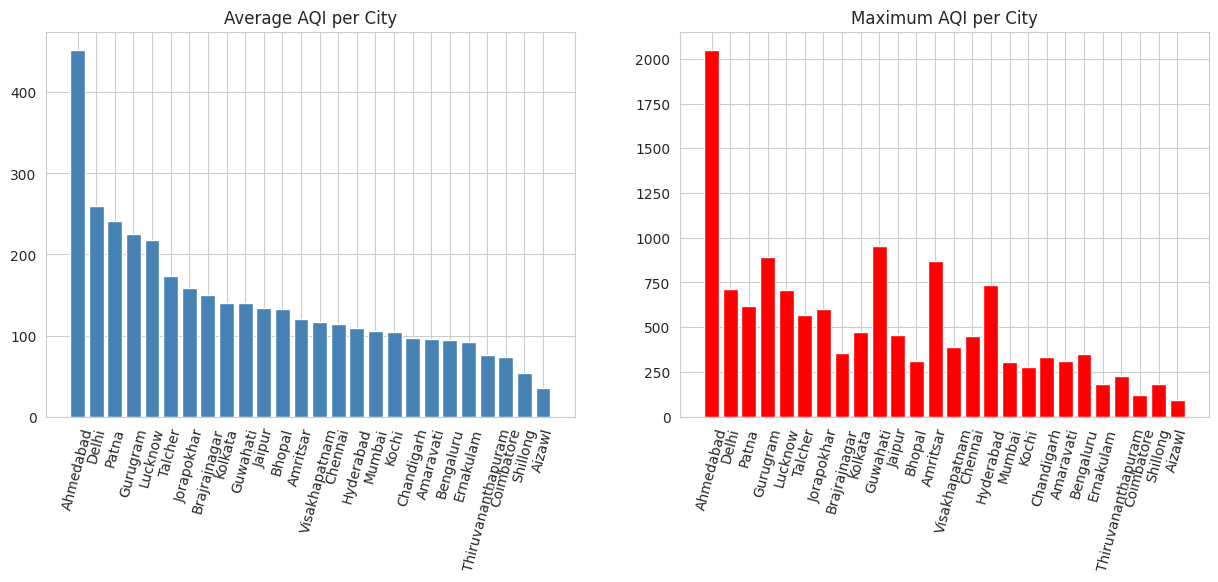

In [35]:
p = city_stats.toPandas()

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

ax[0].bar(p["City"], p["Avg_AQI"], color="steelblue")
ax[0].set_title("Average AQI per City")
ax[0].tick_params(axis="x", rotation=75)

ax[1].bar(p["City"], p["Max_AQI"], color="red")
ax[1].set_title("Maximum AQI per City")
ax[1].tick_params(axis="x", rotation=75)

plt.show()

# 6. Clustering of cities using K-Means (Practical 8 Part B)

Cities are clustered using their average pollutant levels.

(i) Perform clustering

In [36]:
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

cluster_cols = ["PM25", "PM10", "NO2", "CO", "SO2", "O3"]

city_data = pollutant_df.select(["City"] + cluster_cols)
city_data.show(5)

+---------+------+------+-----+-----+-----+-----+
|     City|  PM25|  PM10|  NO2|   CO|  SO2|   O3|
+---------+------+------+-----+-----+-----+-----+
|    Patna| 124.7|119.16|39.06| 1.59|23.84|39.88|
|    Delhi|117.54|232.35|50.76| 1.99|15.84|51.07|
| Gurugram|115.52|183.56|23.73| 1.29| 9.38|35.02|
|  Lucknow|109.77|100.14|33.88| 1.75| 8.02| 37.1|
|Ahmedabad| 67.86|109.19|60.29|22.16|55.71|39.25|
+---------+------+------+-----+-----+-----+-----+
only showing top 5 rows


In [37]:
assembler = VectorAssembler(inputCols=cluster_cols, outputCol="features")
city_data = assembler.transform(city_data)

scaler = StandardScaler(inputCol="features", outputCol="scaledFeatures")
city_data = scaler.fit(city_data).transform(city_data)

city_data.select("City", "scaledFeatures").show(5, truncate=False)

+---------+-----------------------------------------------------------------------------------------------------------------+
|City     |scaledFeatures                                                                                                   |
+---------+-----------------------------------------------------------------------------------------------------------------+
|Patna    |[4.157131997296838,2.486823500614954,2.6404505060431616,0.3816157881827218,2.169749988953866,3.156756090662198]  |
|Delhi    |[3.9184386123678454,4.849055390801314,3.431368860387887,0.4776197600525889,1.4416459658149847,4.042515886412198] |
|Gurugram |[3.8510977412007272,3.8308268023907432,1.6041446622735336,0.3096128092803214,0.8537019671303383,2.77205612575201]|
|Lucknow  |[3.6594096178289806,2.089883395028378,2.29028323463242,0.4200173769306686,0.7299242831967284,2.93670137822386]   |
|Ahmedabad|[2.2622532264359534,2.278753424237553,4.075595519952437,5.318620041590638,5.070334391133384,3.1068875766923

In [38]:
kmeans = KMeans(featuresCol="scaledFeatures", k=3, seed=1)

kmodel = kmeans.fit(city_data)
cluster_pred = kmodel.transform(city_data)

cluster_pred.select("City", "prediction").orderBy("prediction").show(30)

+------------------+----------+
|              City|prediction|
+------------------+----------+
|          Gurugram|         0|
|           Lucknow|         0|
|           Kolkata|         0|
|      Brajrajnagar|         0|
|        Jorapokhar|         0|
|          Guwahati|         0|
|           Talcher|         0|
|            Jaipur|         0|
|          Amritsar|         0|
|            Bhopal|         0|
|     Visakhapatnam|         0|
|         Hyderabad|         0|
|         Amaravati|         0|
|         Bengaluru|         0|
|            Mumbai|         0|
|             Patna|         1|
|             Delhi|         1|
|         Ahmedabad|         1|
|           Chennai|         2|
|        Chandigarh|         2|
|             Kochi|         2|
|        Coimbatore|         2|
|Thiruvananthapuram|         2|
|         Ernakulam|         2|
|          Shillong|         2|
|            Aizawl|         2|
+------------------+----------+



(ii) Visualize the clusters

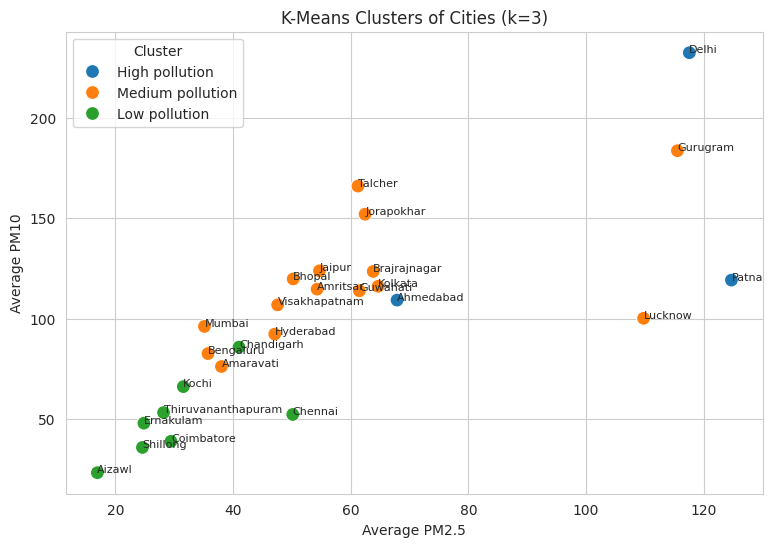

In [39]:
pdf = cluster_pred.select("City", "PM25", "PM10", "NO2", "CO", "SO2", "O3", "prediction").toPandas()

# name the clusters using the average PM2.5 of each cluster
rank = pdf.groupby("prediction")["PM25"].mean().sort_values().index.tolist()
names = dict(zip(rank, ["Low pollution", "Medium pollution", "High pollution"]))
pdf["Cluster"] = pdf["prediction"].map(names)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=pdf, x="PM25", y="PM10", hue="Cluster", s=100)

for i in range(len(pdf)):
    plt.annotate(pdf["City"][i], (pdf["PM25"][i], pdf["PM10"][i]), fontsize=8)

plt.xlabel("Average PM2.5")
plt.ylabel("Average PM10")
plt.title("K-Means Clusters of Cities (k=3)")
plt.show()

(iii) Number of cities in each cluster

In [40]:
cluster_pred.groupBy("prediction").count().show()

for name in ["High pollution", "Medium pollution", "Low pollution"]:
    print(name, ":", pdf[pdf["Cluster"] == name]["City"].tolist())

+----------+-----+
|prediction|count|
+----------+-----+
|         1|    3|
|         2|    8|
|         0|   15|
+----------+-----+

High pollution : ['Patna', 'Delhi', 'Ahmedabad']
Medium pollution : ['Gurugram', 'Lucknow', 'Kolkata', 'Brajrajnagar', 'Jorapokhar', 'Guwahati', 'Talcher', 'Jaipur', 'Amritsar', 'Bhopal', 'Visakhapatnam', 'Hyderabad', 'Amaravati', 'Bengaluru', 'Mumbai']
Low pollution : ['Chennai', 'Chandigarh', 'Kochi', 'Coimbatore', 'Thiruvananthapuram', 'Ernakulam', 'Shillong', 'Aizawl']


(iv) Examine the cluster centers and interpret their meaning

In [41]:
print("Cluster Centers (standardized, order: PM25, PM10, NO2, CO, SO2, O3):")
for i, center in enumerate(kmodel.clusterCenters()):
    print("Cluster", i, "(" + names[i] + "):", center.round(2))

silhouette = ClusteringEvaluator(featuresCol="scaledFeatures").evaluate(cluster_pred)
print()
print("Silhouette Score:", silhouette)

Cluster Centers (standardized, order: PM25, PM10, NO2, CO, SO2, O3):
Cluster 0 (Medium pollution): [2.   2.46 1.69 0.26 1.21 2.62]
Cluster 1 (High pollution): [3.45 3.2  3.38 2.06 2.89 3.44]
Cluster 2 (Low pollution): [1.03 1.05 0.73 0.21 0.77 1.82]

Silhouette Score: 0.3163622626133475


(v) How does changing the value of k affect clustering?

In [42]:
for k in range(2, 7):
    km = KMeans(featuresCol="scaledFeatures", k=k, seed=1)
    km_pred = km.fit(city_data).transform(city_data)
    score = ClusteringEvaluator(featuresCol="scaledFeatures").evaluate(km_pred)
    print("k =", k, " Silhouette Score =", score)

k = 2  Silhouette Score = 0.57957237719556
k = 3  Silhouette Score = 0.3163622626133475
k = 4  Silhouette Score = 0.32239926484753817
k = 5  Silhouette Score = 0.31373430057200485
k = 6  Silhouette Score = 0.31791489067262363


# 7. Prepare files for the Streamlit dashboard

In [43]:

import os
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Create folder
os.makedirs("aqi_app", exist_ok=True)

features = ["PM25", "PM10", "NO2", "CO", "SO2", "O3"]

# City-wise average values
city = df.groupby("City")[["AQI"] + features].mean().reset_index()

# Prepare data
X = city[features].fillna(city[features].median())

# Scale data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train K-Means model
model = KMeans(n_clusters=3, random_state=1, n_init=10)
city["Cluster_ID"] = model.fit_predict(X_scaled)

# Save model files
joblib.dump(model, "aqi_app/kmeans_model.pkl")
joblib.dump(scaler, "aqi_app/scaler.pkl")
joblib.dump(features, "aqi_app/features.pkl")

# Save city data
city.to_csv("aqi_app/city_summary.csv", index=False)

df.groupby(["City", "Year"])["AQI"].mean().reset_index().to_csv(
    "aqi_app/city_year.csv", index=False
)

df.groupby("Month")["AQI"].mean().reset_index().to_csv(
    "aqi_app/monthly.csv", index=False
)

df["AQI_Bucket"].value_counts().rename_axis("AQI_Bucket").reset_index(
    name="Days"
).to_csv("aqi_app/bucket_counts.csv", index=False)

print("All model and CSV files saved successfully!")


All model and CSV files saved successfully!


In [45]:
import os

print(os.listdir("aqi_app"))

['city_year.csv', 'features.pkl', 'kmeans_model.pkl', 'city_summary.csv', 'monthly.csv', 'scaler.pkl', 'bucket_counts.csv']


# 9. Conclusion
The AQI data of Indian cities was cleaned and analysed with statistics, plots and trends. Map-Reduce with PySpark RDD, Spark DataFrame and Spark SQL were used to find the most polluted and cleanest cities, the AQI categories, and the yearly and seasonal trends. K-Means clustering grouped the cities into high, medium and low pollution groups, and the results are shown in a Streamlit dashboard.